# FDA Medical Warning Letters – Scraping & Text Analysis

This notebook collects FDA warning letters related to medical / drug topics and analyzes them with several NLP techniques.

| Section | What it does |
|---|---|
| 0 | Setup – packages and all imports |
| 1 | Scrape the warning letters from the FDA website |
| 2 | Load the scraped letters into memory |
| 3 | Number of letters per year |
| 4 | Dominant clinical keywords (TF-IDF) |
| 5 | Topic clustering with K-Means + TruncatedSVD |
| 6 | Semantic clustering with Sentence-BERT + Hierarchical Clustering + t-SNE |
| 7 | Keywords per semantic cluster (c-TF-IDF) |
| 8 | Zero-Shot classification of enforcement topics with DeBERTa |

## 0. Setup

### 0.1 Install packages
Installs the `statsmodels` and `scipy` packages in case they are missing from the environment (for example in a fresh Colab runtime). You only need to run this once.

In [3]:
!pip3 install statsmodels scipy

### 0.2 Imports
All the libraries used in the notebook are imported here, in one place:
* **Standard library** – JSON, regex, time, paths and URL helpers.
* **Scraping** – `requests` and `BeautifulSoup` for downloading and parsing the FDA pages.
* **Data & plotting** – `pandas`, `numpy`, `matplotlib`, `seaborn`.
* **Machine learning** – `scikit-learn` (TF-IDF, K-Means, SVD, t-SNE) and `scipy` (hierarchical clustering).
* **Deep learning** – `torch`, `sentence-transformers` (SBERT embeddings) and `transformers` (DeBERTa zero-shot classifier).

Internal `RuntimeWarning` / `FutureWarning` messages are silenced so that the output stays clean.

In [4]:
import json
import re
import time
import warnings
from pathlib import Path
from typing import Iterable
from urllib.parse import urljoin

import numpy as np
import pandas as pd
import requests
from bs4 import BeautifulSoup

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

from sklearn.feature_extraction import text
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.manifold import TSNE
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster

import torch
from sentence_transformers import SentenceTransformer
from transformers import pipeline

warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

## 1. Extract Data From the FDA Website

The FDA warning-letters page is backed by a Drupal "datatables" AJAX API. We page through that API, keep only letters issued by medical / drug related offices, and then download the full text of every letter.

### 1.1 API constants
Defines the FDA base URL, the AJAX endpoint (`DT_URL`), the fixed query parameters the endpoint expects (`VIEW_PARAMS`), and a regex (`LETTER_PATH_RE`) that recognizes a valid link to a single warning letter.

In [5]:
BASE_URL = "https://www.fda.gov"
LIST_PATH = (
    "/inspections-compliance-enforcement-and-criminal-investigations/"
    "compliance-actions-and-activities/warning-letters"
)
DT_URL = f"{BASE_URL}/datatables/views/ajax"

VIEW_PARAMS = {
    "_drupal_ajax": 1,
    "_wrapper_format": "drupal_ajax",
    "pager_element": 0,
    "view_args": "",
    "view_base_path": (
        "inspections-compliance-enforcement-and-criminal-investigations/"
        "compliance-actions-and-activities/warning-letters/datatables-data"
    ),
    "view_display_id": "warning_letter_solr_block",
    "view_dom_id": "c6eefb6fe061b4b0d0aac545115623ca9dc74414ec52ab322e1eafc17ee420bd",
    "view_name": "warning_letter_solr_index",
    "view_path": LIST_PATH,
    "total_items": 3474,
}

LETTER_PATH_RE = re.compile(
    r"^/inspections-compliance-enforcement-and-criminal-investigations/warning-letters/[^/?#]+$"
)

### 1.2 Run settings
The run parameters (they replace the original command-line arguments, because `argparse` cannot read arguments inside Jupyter):
* `PAGE_SIZE` – number of rows requested from the API per page.
* `MAX_LETTERS` – scrape only the first N letters (`0` = all of them).
* `DELAY_SECONDS` – pause between letter downloads, to be polite to the server.
* `URLS_OUT` / `JSONL_OUT` – output files for the list of URLs and for the scraped letters.

In [6]:
PAGE_SIZE = 100
MAX_LETTERS = 0
DELAY_SECONDS = 0.4
URLS_OUT = Path("medical_warning_letter_urls.txt")
JSONL_OUT = Path("medical_warning_letters.jsonl")

### 1.3 HTTP session
Creates a `requests.Session` with a regular browser `User-Agent` header, so the FDA server treats our requests like a normal browser and the connection is reused between requests.

In [7]:
def make_session() -> requests.Session:
    session = requests.Session()
    session.headers.update(
        {
            "User-Agent": (
                "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) "
                "AppleWebKit/537.36 (KHTML, like Gecko) "
                "Chrome/125.0.0.0 Safari/537.36"
            )
        }
    )
    return session

### 1.4 Collect the medical letter URLs
`iter_letter_urls` pages through the API. For every row it checks the **Issuing Office** column, and if the office matches one of the medical keywords (CDER, drug, medical, pharmaceutical, clinical, biologics) it extracts the link to the letter from the company column. It returns a sorted list of unique URLs.

In [8]:
def iter_letter_urls(session: requests.Session, page_size: int) -> list[str]:
    start = 0
    draw = 1
    discovered: set[str] = set()
    records_total = None

    # הגדרת מילות מפתח ממוקדות לסינון המשרדים הרפואיים (כמו CDER, Drugs, Medical)
    target_offices = ['cder', 'drug', 'medical', 'pharmaceutical', 'clinical', 'biologics']

    print("🔎 מתחיל לסרוק את ה-API של ה-FDA ומסנן נושאים רפואיים (Medical Service)...")

    while True:
        params = {
            **VIEW_PARAMS,
            "draw": draw,
            "start": start,
            "length": page_size,
        }
        response = session.get(DT_URL, params=params, timeout=60)
        response.raise_for_status()
        payload = response.json()

        if records_total is None:
            records_total = int(payload.get("recordsTotal", 0))
            print(f"recordsTotal reported by API: {records_total}")

        rows = payload.get("data", [])
        if not rows:
            break

        for row in rows:
            if not isinstance(row, list) or len(row) < 4:
                continue

            # שליפת המשרד המנפיק (Issuing Office) מתוך עמודה 4 בטבלה הגולמית
            issuing_office = row[3] if isinstance(row[3], str) else ""

            # בדיקה האם השורה הנוכחית שייכת לנושאים הרפואיים שלנו
            if any(office in issuing_office.lower() for office in target_offices):
                company_cell_html = row[2] if isinstance(row[2], str) else ""
                soup = BeautifulSoup(company_cell_html, "html.parser")
                anchor = soup.find("a", href=True)
                if not anchor:
                    continue

                href = anchor.get("href", "").strip()
                if LETTER_PATH_RE.match(href):
                    discovered.add(urljoin(BASE_URL, href))

        start += page_size
        draw += 1
        print(
            f"🔄 נסרקו {start} שורות באינדקס. קישורים רפואיים ייחודיים שנמצאו עד כה: {len(discovered)}"
        )

        if records_total is not None and start >= records_total:
            break

    return sorted(discovered)

### 1.5 Helper functions
* `load_completed_urls` – reads the existing JSONL output file and returns the URLs that were already downloaded, so a run that was interrupted can continue where it stopped.
* `extract_main_text` – parses a letter's HTML page and returns its title (`<h1>`) and the plain text of the main content.

In [9]:
def load_completed_urls(jsonl_path: Path) -> set[str]:
    if not jsonl_path.exists():
        return set()

    completed = set()
    with jsonl_path.open("r", encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            try:
                obj = json.loads(line)
            except json.JSONDecodeError:
                continue
            url = obj.get("url")
            if isinstance(url, str):
                completed.add(url)
    return completed


def extract_main_text(html: str) -> tuple[str, str]:
    soup = BeautifulSoup(html, "html.parser")
    title_el = soup.find("h1")
    title = title_el.get_text(" ", strip=True) if title_el else ""

    main = soup.find("main") or soup.find("article") or soup.body
    text = main.get_text("\n", strip=True) if main else ""
    return title, text

### 1.6 Download the letters
`scrape_letters` downloads every letter that is not yet in the output file, extracts its title and text, and appends one JSON record per line to the JSONL file. Errors are stored in the record instead of stopping the run, and progress is printed every 25 letters.

In [10]:
def scrape_letters(
        session: requests.Session,
        urls: Iterable[str],
        jsonl_out: Path,
        delay_seconds: float,
) -> None:
    completed = load_completed_urls(jsonl_out)
    pending = [u for u in urls if u not in completed]

    print(f"📦 כבר קיימים בקובץ הפלט הרפואי: {len(completed)} מכתבים.")
    print(f" מכתבים רפואיים חדשים שממתינים להורדה: {len(pending)}")

    with jsonl_out.open("a", encoding="utf-8") as out:
        for idx, url in enumerate(pending, start=1):
            record = {"url": url}
            try:
                resp = session.get(url, timeout=60)
                resp.raise_for_status()
                title, text = extract_main_text(resp.text)
                record.update({"title": title, "text": text})
            except Exception as exc:
                record.update({"error": str(exc)})

            out.write(json.dumps(record, ensure_ascii=False) + "\n")

            if idx % 25 == 0 or idx == len(pending):
                print(f" הורדו בהצלחה {idx}/{len(pending)} מכתבים רפואיים.")

            time.sleep(delay_seconds)

### 1.7 Run step 1 – find and save the URLs
Opens the session, scans the whole API for medical letters, and saves the URL list to `URLS_OUT`. If `MAX_LETTERS` is set, the list is trimmed to the first N URLs.

In [11]:
session = make_session()

urls = iter_letter_urls(session, PAGE_SIZE)
URLS_OUT.write_text("\n".join(urls) + "\n", encoding="utf-8")
print(f" נכתבה רשימת הכתובות הרפואיות המסוננות: {URLS_OUT} ({len(urls)} קישורים)")

if MAX_LETTERS > 0:
    urls = urls[:MAX_LETTERS]
    print(f"Limiting scrape to first {len(urls)} URLs due to MAX_LETTERS")

🔎 מתחיל לסרוק את ה-API של ה-FDA ומסנן נושאים רפואיים (Medical Service)...
recordsTotal reported by API: 3768
🔄 נסרקו 100 שורות באינדקס. קישורים רפואיים ייחודיים שנמצאו עד כה: 50
🔄 נסרקו 200 שורות באינדקס. קישורים רפואיים ייחודיים שנמצאו עד כה: 98
🔄 נסרקו 300 שורות באינדקס. קישורים רפואיים ייחודיים שנמצאו עד כה: 164
🔄 נסרקו 400 שורות באינדקס. קישורים רפואיים ייחודיים שנמצאו עד כה: 211
🔄 נסרקו 500 שורות באינדקס. קישורים רפואיים ייחודיים שנמצאו עד כה: 271
🔄 נסרקו 600 שורות באינדקס. קישורים רפואיים ייחודיים שנמצאו עד כה: 314
🔄 נסרקו 700 שורות באינדקס. קישורים רפואיים ייחודיים שנמצאו עד כה: 365
🔄 נסרקו 800 שורות באינדקס. קישורים רפואיים ייחודיים שנמצאו עד כה: 441
🔄 נסרקו 900 שורות באינדקס. קישורים רפואיים ייחודיים שנמצאו עד כה: 482
🔄 נסרקו 1000 שורות באינדקס. קישורים רפואיים ייחודיים שנמצאו עד כה: 522
🔄 נסרקו 1100 שורות באינדקס. קישורים רפואיים ייחודיים שנמצאו עד כה: 548
🔄 נסרקו 1200 שורות באינדקס. קישורים רפואיים ייחודיים שנמצאו עד כה: 593
🔄 נסרקו 1300 שורות באינדקס. קישורים רפואיים ייחודי

### 1.8 Run step 2 – download the letters
Downloads all the pending letters into `JSONL_OUT`. This step can take a while (one request per letter + the delay).

In [12]:
scrape_letters(session, urls, JSONL_OUT, DELAY_SECONDS)
print(f" הסתיים בהצלחה! קובץ הפלט הרפואי הממוקד מוכן: {JSONL_OUT}")

📦 כבר קיימים בקובץ הפלט הרפואי: 0 מכתבים.
 מכתבים רפואיים חדשים שממתינים להורדה: 1320
 הורדו בהצלחה 25/1320 מכתבים רפואיים.
 הורדו בהצלחה 50/1320 מכתבים רפואיים.
 הורדו בהצלחה 75/1320 מכתבים רפואיים.
 הורדו בהצלחה 100/1320 מכתבים רפואיים.
 הורדו בהצלחה 125/1320 מכתבים רפואיים.
 הורדו בהצלחה 325/1320 מכתבים רפואיים.
 הורדו בהצלחה 350/1320 מכתבים רפואיים.
 הורדו בהצלחה 375/1320 מכתבים רפואיים.
 הורדו בהצלחה 400/1320 מכתבים רפואיים.
 הורדו בהצלחה 425/1320 מכתבים רפואיים.
 הורדו בהצלחה 450/1320 מכתבים רפואיים.
 הורדו בהצלחה 475/1320 מכתבים רפואיים.
 הורדו בהצלחה 500/1320 מכתבים רפואיים.
 הורדו בהצלחה 525/1320 מכתבים רפואיים.
 הורדו בהצלחה 550/1320 מכתבים רפואיים.
 הורדו בהצלחה 575/1320 מכתבים רפואיים.
 הורדו בהצלחה 600/1320 מכתבים רפואיים.
 הורדו בהצלחה 625/1320 מכתבים רפואיים.
 הורדו בהצלחה 650/1320 מכתבים רפואיים.
 הורדו בהצלחה 675/1320 מכתבים רפואיים.
 הורדו בהצלחה 700/1320 מכתבים רפואיים.
 הורדו בהצלחה 725/1320 מכתבים רפואיים.
 הורדו בהצלחה 750/1320 מכתבים רפואיים.
 הורדו בהצלחה 775/13

## 2. Load the Scraped Letters

Reads the JSONL file **once** and keeps it in memory for all the analyses below:
* `records` – the full JSON record of every letter (used later for date extraction).
* `texts` – only the letter texts (records without text, e.g. failed downloads, are skipped).

In [13]:
FILE_PATH = 'medical_warning_letters.jsonl'

records = []
with open(FILE_PATH, 'r', encoding='utf-8') as f:
    for line in f:
        if line.strip():
            records.append(json.loads(line))

texts = [r['text'] for r in records if r.get('text')]
print(f"✅ Successfully loaded {len(texts)} documents.")

✅ Successfully loaded 1320 documents.


## 3. Number of Medical Warning Letters per Year

### 3.1 Extract the year of each letter
Searches the text of each letter with a regex for the first 4-digit year between 2020 and 2026, and uses it as the year the letter was issued.

In [14]:
years = []
for full_text in texts:
    match = re.search(r'\b(202[0-6])\b', full_text)
    if match:
        years.append(int(match.group(1)))

print(f" הצלחנו לחלץ שנה מתוך {len(years)} מכתבים רפואיים.")

 הצלחנו לחלץ שנה מתוך 1320 מכתבים רפואיים.


### 3.2 Count letters per year
Builds a small table (`letters_per_year`) with the number of letters for every year, sorted chronologically.

In [15]:
letters_per_year = pd.DataFrame({'Year': years})['Year'].value_counts().reset_index()
letters_per_year.columns = ['Year', 'Count']
letters_per_year = letters_per_year.sort_values(by='Year')

### 3.3 Bar chart
Draws a clean bar chart on a white background with the exact count written above each bar.

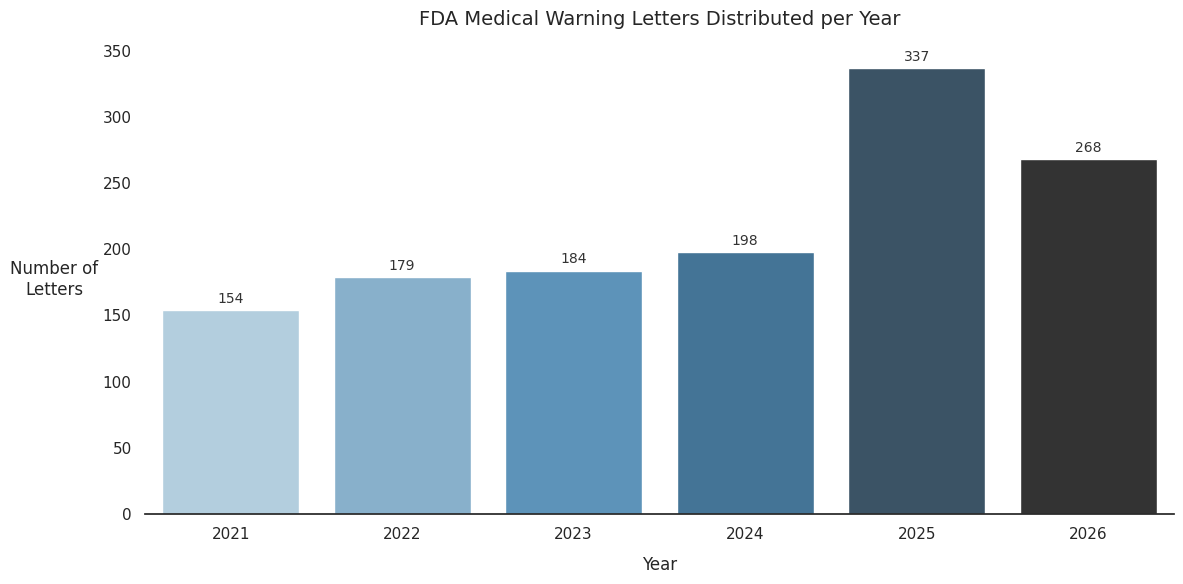

In [16]:
sns.set_theme(style="white")
plt.figure(figsize=(12, 6))

sns.barplot(data=letters_per_year, x='Year', y='Count', hue='Year', palette='Blues_d', legend=False)

plt.title('FDA Medical Warning Letters Distributed per Year', fontsize=14, pad=15, fontweight='medium')
plt.xlabel('Year', fontsize=12, labelpad=10)
plt.ylabel('Number of\nLetters', fontsize=12, labelpad=35, rotation=0, va='center', fontweight='medium')

sns.despine(left=True, bottom=False, top=True, right=True)
plt.xticks(fontsize=11)
plt.yticks(fontsize=11)

# הצגת ערך מספרי מעל כל עמודה בגרף
ax = plt.gca()
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center',
                xytext=(0, 8),
                textcoords='offset points',
                fontsize=10, fontweight='medium', color='#333333')

plt.tight_layout()
plt.show()

### 3.4 Summary table
Prints the number of letters per year as a plain table.

In [17]:
print(" --- סיכום כמות המכתבים הרפואיים לפי שנים ---")
print(letters_per_year.to_string(index=False))

 --- סיכום כמות המכתבים הרפואיים לפי שנים ---
 Year  Count
 2021    154
 2022    179
 2023    184
 2024    198
 2025    337
 2026    268


## 4. Appendix A: Dominant Clinical Keywords (TF-IDF Weights)

Finds the 30 most dominant clinical terms and substances in the letters, after aggressively removing the fixed regulatory / legal phrases ("noise") that appear in every FDA letter.

### 4.1 Extended stop words
A list of English stop words plus hundreds of regulatory and technical words (e.g. *fda, letter, section, sincerely, cgmp*). These words appear in almost every letter and say nothing about its specific topic, so they are removed. The same list is reused in section 5.

In [18]:
base_stop_words = text.ENGLISH_STOP_WORDS.union([
    'fda', 'act', 'letter', 'firm', 'section', 'products', 'product', 'compliance',
    'received', 'response', 'inspections', 'investigations', 'food', 'drug', 'drugs',
    'administration', 'intended', 'use', 'violation', 'violations', 'substance',
    'substances', 'requirements', 'prohibited', 'commerce', 'interstate', 'within',
    'days', 'working', 'office', 'sincerely', 'director', 'center', 'care', 'adulterated',
    'misbranded', 'insanitary', 'conditions', 'cgmp', 'current', 'good', 'manufacturing',
    'practice', 'regulations', 'facility', 'inspection', 'investigator', 'review',
    'observed', 'specific', 'including', 'failure', 'failed', 'establish', 'procedures',
    'written', 'assure', 'identity', 'strength', 'quality', 'purity', 'regulatory',
    'legal', 'action', 'actions', 'address', 'steps', 'taken', 'correct', 'prevent',
    'recurrence', 'conclusions', 'investigate', 'thoroughly', 'unexplained',
    'discrepancy', 'batch', 'component', 'components', 'meet', 'specifications',
    'distributed', 'lots', 'lot', 'testing', 'test', 'results', 'analytical',
    'laboratory', 'records', 'record', 'control', 'controls', 'unit', 'responsibility',
    'authority', 'approve', 'reject', 'refer', 'case', 'number', 'date', 'dated',
    'title', 'label', 'labeling', 'website', 'internet', 'offers', 'sale', 'introduced',
    'solution', 'solutions', 'delivered', 'introduction', 'violates', 'sections',
    'meaning', 'federal', 'cosmetic', 'approved', 'application', 'applications',
    'effect', 'pursuant', 'evident', 'basis', 'legally', 'marketed', 'without',
    'gdufa', 'generic', 'user', 'fee', 'amendments', 'reauthorization', 'fiscal',
    'years', 'iii', 'commitment', 'eligible', 'post', 'meeting', 'obtain',
    'preliminary', 'feedback', 'adequacy', 'completeness', 'plans', 'content',
    'regulated', 'certified', 'medically', 'supervised', 'healthcare', 'setting',
    'hospitals', 'surgical', 'centers', 'emergency', 'departments', 'management',
    'acute', 'pain', 'severe', 'enough', 'require', 'opioid', 'analgesic',
    'alternative', 'treatments', 'inadequate', 'href', 'com', 'b4', 'variant',
    'url', 'http', 'https', 'ampoule', 'www', 'net', 'org', 'dear', 'mr', 'ms',
    'dr', 'attention', 'att', 'warning', 'include', 'unapproved', 'ensure',
    'appropriate', 'new', 'provide', 'hand', 'process', 'data', 'information',
    'stated', 'noted', 'determine', 'found', 'described', 'regarding',
    'additionally', 'regard', 'follows', 'following', 'referred', 'indicated',
    'requires', 'provides', 'determines', 'available', 'additional', 'conducted',
    'required', 'documents', 'documentation', 'submit', 'submitted', 'copies',
    'copy', 'evidence', 'implementation', 'evaluate', 'evaluation', 'reviewed',
    'assessment', 'necessary', 'time', 'listed', 'items', 'item', 'paragraph',
    'order', 'clearly', 'subject', 'provisions', 'contained', 'issue', 'issued',
    'receive', 'sending', 'sent', 'reply', 'replying', 'contact', 'finally',
    'know', 'bring', 'closeout', 'observations', 'applicable', 'laws', 'serious',
    'problems', 'systems', 'prompt', 'marketing', 'distribute', 'sell', 'sold',
    'distribution', 'commercial', 'cfr', 'part', 'parts', 'subpart', 'title21',
    '21cfr', 'statute', 'did', 'used', 'plan', 'program', 'gov', 'recipient',
    'letters', 'fdca', 'adequate', 'research', 'risk', 'equipment', 'corrective',
    'manufacture', 'limited', 'health', 'treatment', 'devices', 'device', 'person',
    'audit', 'protocol', 'procedure', 'report', 'reports', 'standard', 'standards',
    'method', 'methods', 'parameter', 'parameters', 'specification', 'preventive',
    'capa', 'sop', 'master', 'production', 'operations', 'performed', 'personnel',
    'staff', 'trained', 'training', 'qualification', 'validated', 'released',
    'quarantine', 'sampling', 'sample', 'samples', 'collected', 'collection',
    'analysis', 'analyzed', 'tested', 'tester', 'third', 'party', 'vendor',
    'supplier', 'contract', 'site', 'sites', 'line', 'lines', 'room', 'rooms',
    'area', 'areas', 'zone', 'zones', 'environment', 'environmental',
    'active', 'particular', 'clinical', 'ingredient', 'ingredients',
    'concerning', 'conduct', 'misleading', 'chemical', 'immediate', 'clean',
    'covid', 'coronavirus', 'validate', 'validation', 'periodic', 'initial',
    'comprehensive', 'based', 'receipt',

    # חסימת מילים בודדות חונקות (כדי לאלץ הצגת ביגרמים/טריגרמים מורכבים יותר)
    'compounding', 'remediation', 'sanitizer', 'sanitizers'
])

### 4.2 Text preprocessing
`preprocess` removes URLs, standalone numbers and every non-letter character, collapses whitespace and lower-cases the text. The cleaned texts (`clean_texts`) are used in sections 4 and 5.

In [19]:
def preprocess(text_in):
    text_in = re.sub(r'https?://\S+|www\.\S+', ' ', text_in)
    text_in = re.sub(r'\b\d+\b', ' ', text_in)
    text_in = re.sub(r'[^a-zA-Z\s]', ' ', text_in)
    text_in = re.sub(r'\s+', ' ', text_in).strip()
    return text_in.lower()


clean_texts = [preprocess(t) for t in texts]
print("🧹 טקסטים נוקו.")

🧹 טקסטים נוקו.


### 4.3 N-gram blacklist and clinical roots
* `NGRAM_BLACKLIST` – specific word pairs/triples that slipped through the stop words but are still noise.
* `clinical_roots` – word roots (e.g. *steril, contamin, semaglu*) used as a semantic filter: only terms that contain one of these roots are kept.

In [20]:
NGRAM_BLACKLIST = {
    'misleading particular', 'concerning compounded', 'conduct clinical',
    'chemical microbiological', 'clinical studies', 'cure covid',
    'disease covid', 'coronavirus disease', 'remediation given',
    'remediated stability', 'contents compoundinginspections',
    'based sanitizers', 'based sanitizer', 'receipt compounding',
    'validation periodic',

    # ניקוי ביטויים כפולים או משובשים מהריצה האחרונה
    'compoundinginspections', 'repreparation', 'remediation given',
    'given remediation', 'given specific'
}

# ─── 3. שורשים קליניים (Clinical Semantic Filter) ─────────────────────────
clinical_roots = [
    'steril', 'contamin', 'microbio', 'semaglu', 'tirzepa', 'infect', 'bacteri',
    'virus', 'viral', 'aseptic', 'impurit', 'validat', 'stabil', 'potenc', 'assay',
    'sanitiz', 'hygien', 'endotoxin', 'pyrogen', 'toxic', 'dosage', 'formulat',
    'capsule', 'tablet', 'inject', 'vial', 'lyophil', 'reconstitut', 'excipient',
    'preservat', 'antibiotic', 'pathogen', 'fungal', 'fungi', 'bioburden',
    'autoclave', 'depyrogenat', 'cleanroom', 'endotox', 'microbial', 'particul',
    'semaglutide', 'tirzepatide'
]

### 4.4 Unigram TF-IDF
Runs TF-IDF on single words (4+ letters). `max_df=0.60` drops words that appear in more than 60% of the letters, `min_df` drops very rare words, and `sublinear_tf=True` dampens words that are repeated many times in the same letter. The total weight of each word across all letters is stored in `df_uni`.

In [21]:
n_docs = len(clean_texts)
common_kwargs = dict(
    stop_words=list(base_stop_words),
    token_pattern=r'\b[a-zA-Z]{4,}\b',
    max_features=3000,
    max_df=0.60,
    min_df=max(2, int(n_docs * 0.01)),
    sublinear_tf=True,
)

# חילוץ Unigrams
tfidf_uni = TfidfVectorizer(ngram_range=(1, 1), **common_kwargs)
mat_uni   = tfidf_uni.fit_transform(clean_texts)
df_uni = pd.DataFrame({
    'Term':   tfidf_uni.get_feature_names_out(),
    'Weight': np.array(mat_uni.sum(axis=0)).flatten(),
    'Type':   'Unigram',
})

### 4.5 Bigram + Trigram TF-IDF
Runs the same TF-IDF on 2- and 3-word phrases, labels each phrase as `Bigram` or `Trigram`, and merges everything with the unigrams into one table (`all_df`).

In [22]:
tfidf_nbi = TfidfVectorizer(ngram_range=(2, 3), **common_kwargs)
mat_nbi   = tfidf_nbi.fit_transform(clean_texts)

def get_ngram_type(term):
    words = term.split()
    if len(words) == 2:
        return 'Bigram'
    elif len(words) >= 3:
        return 'Trigram'
    return 'Unigram'

df_nbi = pd.DataFrame({
    'Term':   tfidf_nbi.get_feature_names_out(),
    'Weight': np.array(mat_nbi.sum(axis=0)).flatten(),
})
df_nbi['Type'] = df_nbi['Term'].apply(get_ngram_type)

all_df = pd.concat([df_uni, df_nbi], ignore_index=True)

### 4.6 Clinical filter, blacklist and length weighting
Keeps only clinical terms, removes the blacklisted phrases, and boosts longer phrases (Bigram ×1.4, Trigram ×1.8) because they carry more specific meaning. The 30 strongest terms are kept in `top_df`, and the top 25 are printed.

In [24]:
def is_clinical(term):
    t = term.lower()
    return any(root in t for root in clinical_roots)

filtered = all_df[all_df['Term'].apply(is_clinical)].copy()

filtered = filtered[~filtered['Term'].isin(NGRAM_BLACKLIST)].copy()

def adj_weight(row):
    if row['Type'] == 'Trigram':
        return row['Weight'] * 1.8
    elif row['Type'] == 'Bigram':
        return row['Weight'] * 1.4
    return row['Weight']

filtered['AdjWeight'] = filtered.apply(adj_weight, axis=1)
# שליפת 30 הביטויים המזוקקים ביותר
top_df = filtered.sort_values('AdjWeight', ascending=False).head(30)

# ─── 9. הדפסת תוצאות מזוקקות לטרמינל ────────────────────────────────────────
print("\n🏆 --- Top 25 Deep Clinical & Microbiological Terms ---")
print(top_df[['Term', 'Type', 'AdjWeight']].head(25).to_string(index=False))


🏆 --- Top 25 Deep Clinical & Microbiological Terms ---
                              Term    Type  AdjWeight
                       semaglutide Unigram  31.095486
                     contamination Unigram  29.343496
compounded semaglutide tirzepatide Trigram  27.543068
            compounded semaglutide  Bigram  26.917616
                         stability Unigram  25.753468
           semaglutide tirzepatide  Bigram  25.613548
                aseptic processing  Bigram  25.465149
                       tirzepatide Unigram  25.033314
                   microbiological Unigram  22.130162
     claims compounded semaglutide Trigram  20.511040
                         microbial Unigram  19.788321
                           sterile Unigram  19.049026
                      contaminated Unigram  18.095547
                           aseptic Unigram  15.492545
               cross contamination  Bigram  14.472565
           microbial contamination  Bigram  13.868459
                        im

### 4.7 Horizontal bar chart
Plots the 30 terms as horizontal bars (strongest at the top), colored by type: blue = unigram, red = bigram, orange = trigram.

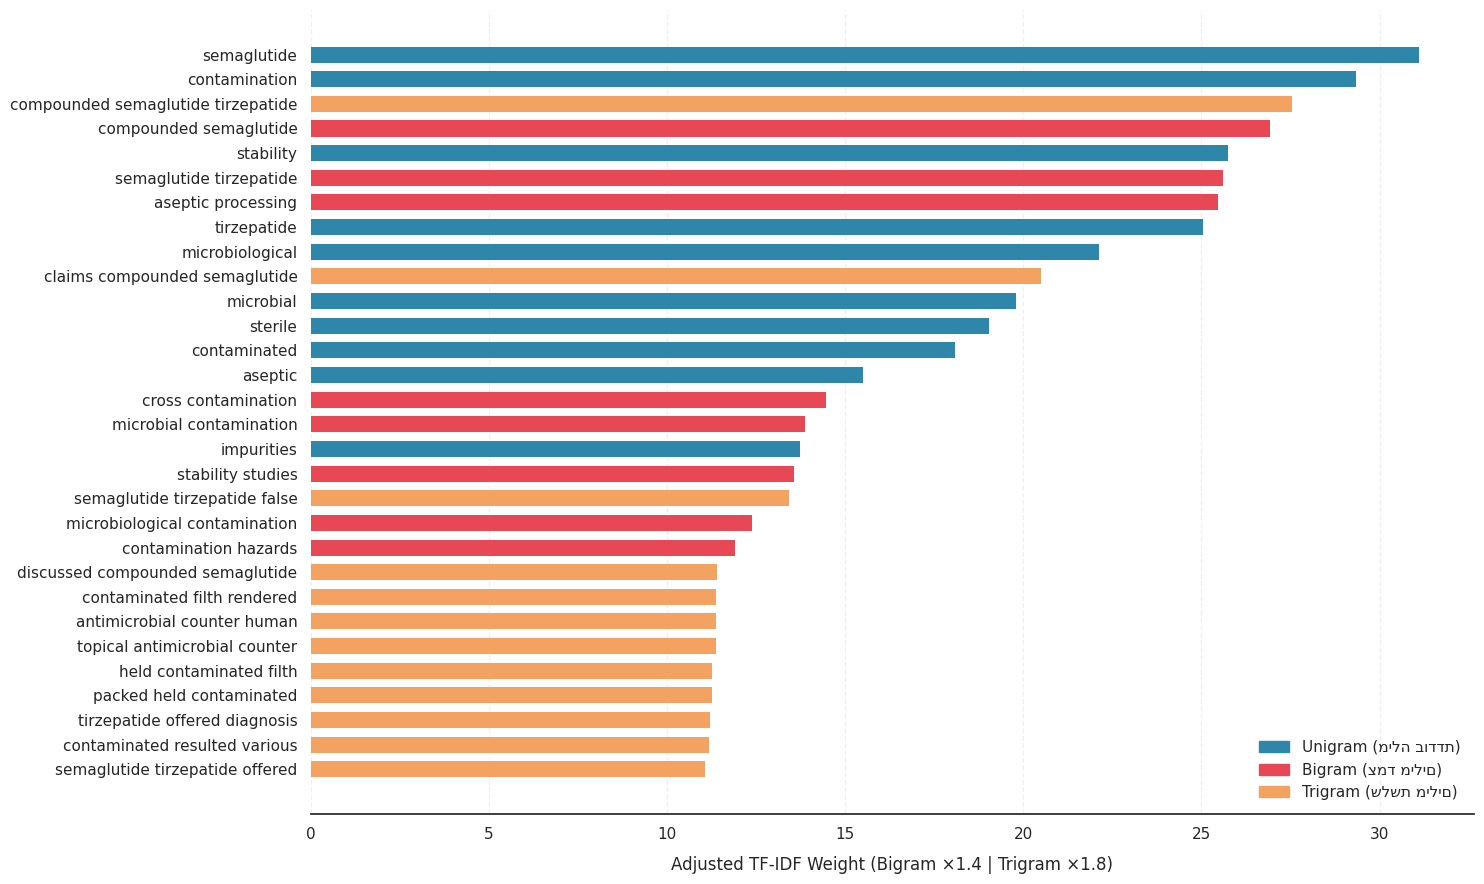

In [25]:
sns.set_theme(style="white")
fig, ax = plt.subplots(figsize=(15, 9))

# הגדרת פלטת צבעים קבועה ומקצועית לכל ישות
palette = {'Unigram': '#2E86AB', 'Bigram': '#E84855', 'Trigram': '#F4A261'}
colors  = [palette[t] for t in top_df['Type']]

# ציור הגרף האופקי
ax.barh(top_df['Term'], top_df['AdjWeight'], color=colors, edgecolor='none', height=0.65)

# עיצוב כותרות וצירים תואם
ax.set_xlabel('Adjusted TF-IDF Weight (Bigram ×1.4 | Trigram ×1.8)', fontsize=12, labelpad=10)

# הסרת קווי התיבה העליונים והימניים לקבלת עיצוב נקי ומודרני
sns.despine(left=True, right=True, top=True, bottom=False)

ax.invert_yaxis()  # דואג שהערכים הגבוהים יהיו למעלה
ax.tick_params(axis='y', labelsize=11)
ax.tick_params(axis='x', labelsize=11)
ax.xaxis.grid(True, linestyle='--', alpha=0.3)
ax.set_axisbelow(True)

# הוספת מקרא צבעים (Legend) מותאם אישית
legend_patches = [
    mpatches.Patch(color='#2E86AB', label='Unigram (מילה בודדת)'),
    mpatches.Patch(color='#E84855', label='Bigram (צמד מילים)'),
    mpatches.Patch(color='#F4A261', label='Trigram (שלשת מילים)'),
]
ax.legend(handles=legend_patches, fontsize=11, frameon=False, loc='lower right')

plt.tight_layout()
plt.show()

# ניתוח מכתבי אזהרה של ה-FDA באמצעות למידה לא מונחית (Unsupervised Learning)

בלוק קוד זה מבצע **ניתוח טקסט מתקדם וגילוי נושאים אוטומטי (Topic Clustering)** על קובץ המכיל מכתבי אזהרה רשמיים של ה-FDA (מנהל המזון והתרופות האמריקאי).

במקום לקרוא אלפי מסמכים משפטיים ארוכים באופן ידני, האלגוריתם מפה את המכתבים, מוצא אילו מהם עוסקים בנושאים דומים, ומציג אותם בצורה גרפית לפי קבוצות בעלות אפיון משותף.

---

## 🛠️ שלבי תהליך הניתוח בקוד

### 1. ניקוי רעשים וסינון מילים (Preprocessing & Stop Words)
מכתבים רשמיים מכילים מילים קבועות רבות שאינן תורמות להבנת המהות הנושאית (כמו: *Sincerely, Director, Section, Website, Facility*).
* הקוד משתמש ברשימה מורחבת של **מילות עצירה (Stop Words)** ומסיר אותן.
* בנוסף, מתבצע ניקוי של קישורי אינטרנט (URLs), מספרים, סימני פיסוק והמרת כל הטקסט לאותיות קטנות (Lowercase).

### 2. מדידת חשיבות המילים (`TF-IDF Vectorization`)
הטקסט הנקי מומר למטריצה מספרית בעזרת שיטת **TF-IDF**.
* השיטה מודדת את חשיבותן של מילים בודדות (*Unigrams*) וצמדי מילים (*Bigrams* - למשל `compounded semaglutide`).
* היא מעניקה משקל גבוה למילים ייחודיות ורפואיות (כמו שם של תרופה), ומשקל נמוך למילים נפוצות מדי שמופיעות בכל מכתב.
* נעשה שימוש בפרמטר `sublinear_tf=True` כדי למתן את ההשראה של מילים שחוזרות על עצמן המון פעמים באותו מכתב.

### 3. חלוקה אוטומטית לקבוצות נושאים (`K-Means Clustering`)
אלגוריתם ה-**K-Means** בוחן את דפוסי המילים ומחלק את כל המכתבים ל-**3 קבוצות עיקריות (Clusters)** ללא התערבות אנושית.
* מכתבים שמסווגים לאותו הקלאסטר מכילים אוצר מילים דומה, מה שמעיד על כך שהם עוסקים בסוג עבירה או תחום רגולטורי דומה.

### 4. הורדת ממדים יציבה (`TruncatedSVD`)
מאחר ומחשב מנתח מילים במרחב מתמטי המורכב מאלפי ממדים (כל מילה/ביגרם ייחודיים הם ממד), בני אדם אינם מסוגלים לראות זאת.
* הקוד משתמש ב-**`TruncatedSVD`** (המוכר גם כ-LSA - Latent Semantic Analysis) כדי לכווץ את המרחב הרב-ממדי ל-2 ממדים בלבד ($X$ ו-$Y$).
* **מדוע TruncatedSVD ולא PCA קלאסי?** טכניקה זו עובדת ישירות על מטריצות דלילות (Sparse Matrices). היא מונעת את הצורך להמיר את המידע למטריצה צפופה וכבדה בזיכרון, ובכך פותרת שגיאות קריסה וגלישה נומרית (`Mathematical Overflow`).

### 5. ויזואליזציה והצגת התוצאות (`Data Visualization`)
בשלב האחרון, הקוד מייצר גרף פיזור (Scatter Plot) באמצעות `matplotlib` ו-`seaborn`:
* **כל נקודה בגרף** מייצגת מכתב אזהרה בודד.
* **המרחק בין הנקודות** משקף את מידת הדמיון בתוכן (מכתבים קרובים = תוכן דומה).
* **צבע הנקודה** נקבע לפי הקלאסטר אליו המכתב שויך, ומקרא הגרף (Legend) מציג את מילות המפתח המובילות שהגדירו כל נושא.

### 5.1 TF-IDF matrix (unigrams + bigrams)
Converts the cleaned texts from section 4.2 into a TF-IDF matrix of single words and word pairs, using the same stop words from section 4.1.

In [26]:
print("📊 Running TF-IDF Vectorization (N-grams Range: 1-2)...")
tfidf = TfidfVectorizer(
    stop_words=list(base_stop_words),
    token_pattern=r'\b[a-zA-Z]{4,}\b',
    ngram_range=(1, 2),
    max_df=0.60,
    min_df=5,
    sublinear_tf=True
)
tfidf_matrix = tfidf.fit_transform(clean_texts)
feature_names = tfidf.get_feature_names_out()

📊 Running TF-IDF Vectorization (N-grams Range: 1-2)...


### 5.2 Train K-Means
Splits the letters into 3 clusters based on their TF-IDF vectors. `random_state=42` makes the result reproducible and `n_init=10` runs the algorithm 10 times and keeps the best result.

In [27]:
num_clusters = 3
print(f"🧬 Training K-Means Model for {num_clusters} Topic Clusters...")
kmeans = KMeans(n_clusters=num_clusters, random_state=42, n_init=10)
kmeans.fit(tfidf_matrix)
kmeans_labels = kmeans.labels_

🧬 Training K-Means Model for 3 Topic Clusters...


### 5.3 Keywords that define each cluster
For each cluster, takes the 3 terms with the highest weight in the cluster center and uses them as the cluster name in the legend.

In [28]:
order_centroids = kmeans.cluster_centers_.argsort()[:, ::-1]
topic_names = []

print("🎯 === Core Keywords Defining Each Cluster ===")
for i in range(num_clusters):
    top_words = [feature_names[ind] for ind in order_centroids[i, :3]]
    topic_label = f"Cluster {i+1}: " + " + ".join(top_words)
    topic_names.append(topic_label)
    print(f"📁 {topic_label}")

🎯 === Core Keywords Defining Each Cluster ===
📁 Cluster 1: compounded + semaglutide + compounded semaglutide
📁 Cluster 2: consultant + guidance + manufactured
📁 Cluster 3: disease + public + concerns


### 5.4 Reduce to 2 dimensions with TruncatedSVD
Compresses the thousands of TF-IDF dimensions into 2 coordinates (x, y) so each letter can be drawn as a point. TruncatedSVD works directly on the sparse matrix, so it avoids the memory and overflow problems of a regular PCA.

In [29]:
svd = TruncatedSVD(n_components=2, random_state=42)
svd_result = svd.fit_transform(tfidf_matrix)

df_svd = pd.DataFrame({
    'x': svd_result[:, 0],
    'y': svd_result[:, 1],
    'Cluster': kmeans_labels
})

### 5.5 Scatter plot of the clusters
Every point is one warning letter, colored by its K-Means cluster. Points that are close together have similar content.

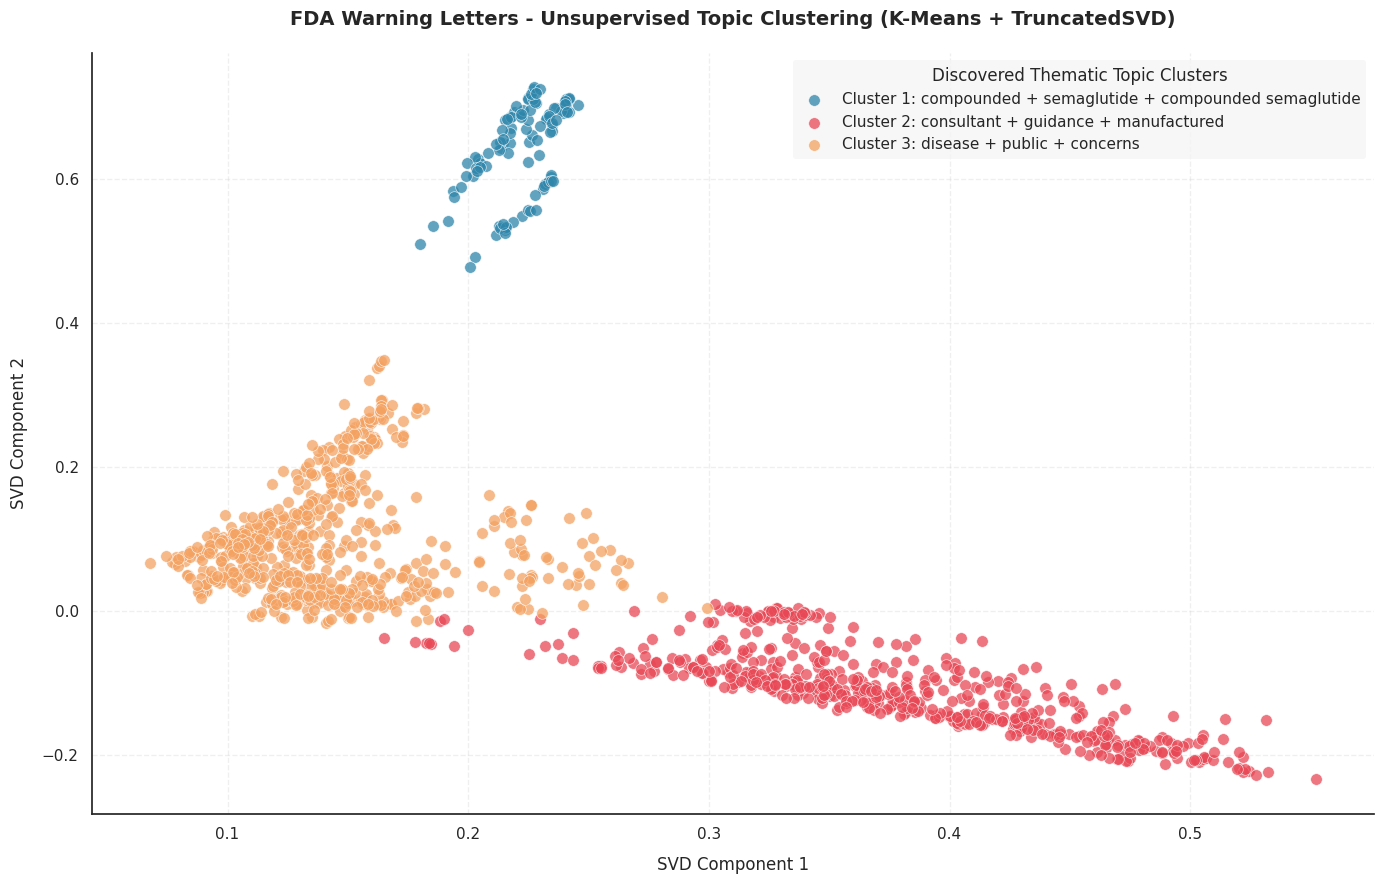

In [ ]:
sns.set_theme(style="white")
plt.figure(figsize=(14, 9))

cluster_colors = ['#2E86AB', '#E84855', '#F4A261']

for i in range(num_clusters):
    cluster_data = df_svd[df_svd['Cluster'] == i]
    plt.scatter(
        cluster_data['x'], cluster_data['y'],
        color=cluster_colors[i],
        label=topic_names[i],
        alpha=0.75,
        edgecolors='w',
        s=70,
        linewidths=0.5
    )

plt.title('FDA Warning Letters - Unsupervised Topic Clustering (K-Means + TruncatedSVD)', fontsize=14, pad=20, fontweight='semibold')
plt.xlabel('SVD Component 1', fontsize=12, labelpad=10)
plt.ylabel('SVD Component 2', fontsize=12, labelpad=10)
sns.despine(top=True, right=True, left=False, bottom=False)
plt.grid(True, linestyle='--', alpha=0.3)
plt.legend(title="Discovered Thematic Topic Clusters", title_fontsize=12, fontsize=11, loc='upper right', frameon=True, facecolor='whitesmoke', edgecolor='none')

plt.tight_layout()
plt.show()

# ניתוח סמנטי מתקדם והיררכי של מכתבי אזהרה (FDA)

בלוק קוד זה מיישם ארכיטקטורה מתקדמת של **למידה עמוקה (Deep Learning)** וטכניקות גיאומטריות מתמטיות על מנת לנתח, לקבץ ולמפות את מכתבי האזהרה של ה-FDA מ-5 השנים האחרונות.

בניגוד לשיטות קלאסיות הסופרות מילים בודדות (כמו TF-IDF), תהליך זה מתמקד ב**הבנת ההקשר והמשמעות הסמנטית (Semantic Context)** של המסמכים, ומציג את מבנה העומק של עולמות התוכן הרגולטוריים.

---

## 🧠 שלבי הארכיטקטורה והאלגוריתמים בקוד

### 1. חישוב וקטורים סמנטיים (`Sentence-BERT Embeddings`)
זהו הלב המדעי של התהליך. הקוד משתמש במודל שפה קדם-מאומן עמוק מסוג **Sentence-BERT** (`all-MiniLM-L6-v2`).
* **פעולה:** המודל קורא כל מכתב אזהרה וממיר אותו למרחב וקטורי צפוף (מטריצה מספרית רב-ממדית).
* **היתרון הסמנטי:** הוקטור מייצג את *המשמעות* של המכתב ולא את המילים הספציפיות. לדוגמה: מכתב שמשתמש במילה *Medication* ומכתב שמשתמש במילה *Pharmaceutical* ימוקמו קרוב מאוד זה לזה במרחב, מכיוון שהמודל מבין שהקשר התוכן שלהם זהה.

### 2. בניית אילן יוחסין למסמכים (`Hierarchical Clustering`)
לאחר שהמסמכים מיוצגים כוקטורים, האלגוריתם מריץ קלסטרינג היררכי בשיטת **Ward's Method** (הממזערת את השונות בתוך הקבוצות).
* **פעולה:** האלגוריתם מתחיל ברמת המסמך הבודד וממזג בכל שלב את שני המסמכים (או קבוצות המסמכים) הקרובים ביותר זה לזה מבחינה סמנטית.
* **תוצאה:** נוצר מבנה עץ היררכי רציף (Dendrogram) המראה כיצד תתי-נושאים קטנים וספציפיים מתחברים בהדרגה לנושאי-על רחבים. בקוד זה, העץ נחתך בצורה אופקית כדי להגדיר בדיוק **3 קלאסטרים מרכזיים**.

### 3. כיווץ ממדים לא-ליניארי (`t-SNE Projection`)
וקטורי השפה קיימים במרחב מתמטי מורכב בעל מאות ממדים, אותו בני אדם אינם מסוגלים לתפוס ויזואלית.
* **פעולה:** אלגוריתם ה-**t-SNE** (t-Distributed Stochastic Neighbor Embedding) מבצע הפחתת ממדים לדו-ממד ($X$ ו-$Y$).
* **הבדל מ-PCA:** בניגוד ל-PCA שהוא ליניארי, t-SNE שומר בצורה קפדנית על "השכנים הקרובים ביותר". הוא לוקח את הציפופים הסמנטיים המורכבים ודוחס אותם למפה אינטואיטיבית, המייצרת "איים נושאיים" מבודדים וברורים על הגרף.
* **תיקון יציבות:** האתחול הוגדר כ-`init='random'` כדי למנוע קריסות וגלישות נומריות (Overflow) שהיו מתרחשות באתחול PCA על דאטה טקסטואלי דליל.

---

## 📊 מבנה המיצג הוויזואלי (Subplots)

הקוד מפיק חלון תצוגה אחוד המציג את הדאטה משתי זוויות משלימות:

1. **הגרף השמאלי (t-SNE Scatter Plot):**
   * **מה רואים:** מפה דו-ממדית שבה כל נקודה מייצגת מכתב אזהרה בודד.
   * **המשמעות:** נקודות המקובצות יחד כ"אי" מייצגות מכתבים בעלי משמעות זהה. הצבעים משקפים את 3 הקבוצות הראשיות שנקבעו על ידי המודל ההיררכי.

2. **הגרף הימני (Hierarchical Dendrogram):**
   * **מה רואים:** תרשים עץ הפוך (אילן יוחסין סטטיסטי).
   * **המשמעות:** ציר ה-$Y$ מייצג את המרחק (חוסר הדמיון) בין הנושאים. ככל ששני ענפים מתחברים נמוך יותר, כך הנושאים שלהם קרובים ודומים יותר בשטח. המספרים בסוגריים בתחתית מייצגים את כמות המסמכים המשויכים לכל ענף.

---

## 🎯 תובנות ומסקנות מהמודל המשולב
שילוב המודלים הללו מאפשר להסיק מסקנות רגולטוריות מובהקות לגבי מגמות האכיפה של ה-FDA ב-5 השנים האחרונות:
* **קלאסטר 1 (כשלי איכות וייצור - cGMP):** מתמקד במפעלי פארמה ותיקים וכשלים תעשייתיים בבדיקות מעבדה ובקרת איכות.
* **קלאסטר 2 (שיווק מטעה באינטרנט - Misbranding):** מבודד חברות תוספי תזונה וקוסמטיקה המוכרות מוצרים אונליין תחת הבטחות שווא רפואיות לרפואת מחלות ללא אישור.
* **קלאסטר 3 (מגיפת הקורונה ואלכוג'ל):** תת-נושא ייחודי וחדש יחסית, המייצג את גל האכיפה המאסיבי נגד יצרני חטאי ידיים (Hand Sanitizers) מזויפים או רעילים שנולדו בתקופת המגיפה.

### 6.1 Light cleaning for embeddings
Language models understand full sentences, so here we only remove URLs and extra whitespace (no stop-word removal or lower-casing).

In [30]:
def clean_for_embedding(text_in):
    text_in = re.sub(r'https?://\S+|www\.\S+', ' ', text_in)
    text_in = re.sub(r'\s+', ' ', text_in).strip()
    return text_in


embedding_texts = [clean_for_embedding(t) for t in texts]

### 6.2 Compute Sentence-BERT embeddings
Loads the pre-trained `all-MiniLM-L6-v2` model and converts every letter into a dense vector that represents its meaning. The model is kept in `sbert_model` and reused in section 7.

In [ ]:
print("🧠 מחשב Embeddings סמנטיים בעזרת מודל שפה (Sentence-BERT)...")
sbert_model = SentenceTransformer('all-MiniLM-L6-v2')
embeddings = sbert_model.encode(embedding_texts, show_progress_bar=False)
print(f"✅ נוצרה מטריצת וקטורים בגודל: {embeddings.shape}")

🧠 מחשב Embeddings סמנטיים בעזרת מודל שפה (Sentence-BERT)...


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

✅ נוצרה מטריצת וקטורים בגודל: (1320, 384)


### 6.3 Hierarchical clustering (Ward's method)
Builds the linkage matrix `Z` (the full merge tree of the documents), then cuts the tree into 3 main clusters. The labels are shifted to start from 0.

In [ ]:
print("🧬 מריץ קלסטרינג היררכי ומחשב מטריצת קישורים (Linkage Matrix)...")
Z = linkage(embeddings, method='ward')

num_clusters = 3
hier_labels = fcluster(Z, t=num_clusters, criterion='maxclust') - 1

🧬 מריץ קלסטרינג היררכי ומחשב מטריצת קישורים (Linkage Matrix)...


### 6.4 Reduce to 2 dimensions with t-SNE
Projects the embeddings to 2D with t-SNE, which keeps semantically close letters close to each other on the map. `init='random'` avoids the numeric overflow that PCA initialization caused.

In [ ]:
print("📉 מוריד ממדים באמצעות t-SNE לצורך ויזואליזציה...")
tsne = TSNE(n_components=2, perplexity=30, init='random', random_state=42, max_iter=1000)
tsne_result = tsne.fit_transform(embeddings)

df_tsne = pd.DataFrame({
    'x': tsne_result[:, 0],
    'y': tsne_result[:, 1],
    'Cluster': hier_labels
})

📉 מוריד ממדים באמצעות t-SNE לצורך ויזואליזציה...


### 6.5 t-SNE map + dendrogram
Draws two plots side by side: on the left the t-SNE map colored by cluster, and on the right the dendrogram (the last 30 merges of the tree), where the height of a merge shows how different the merged groups are.

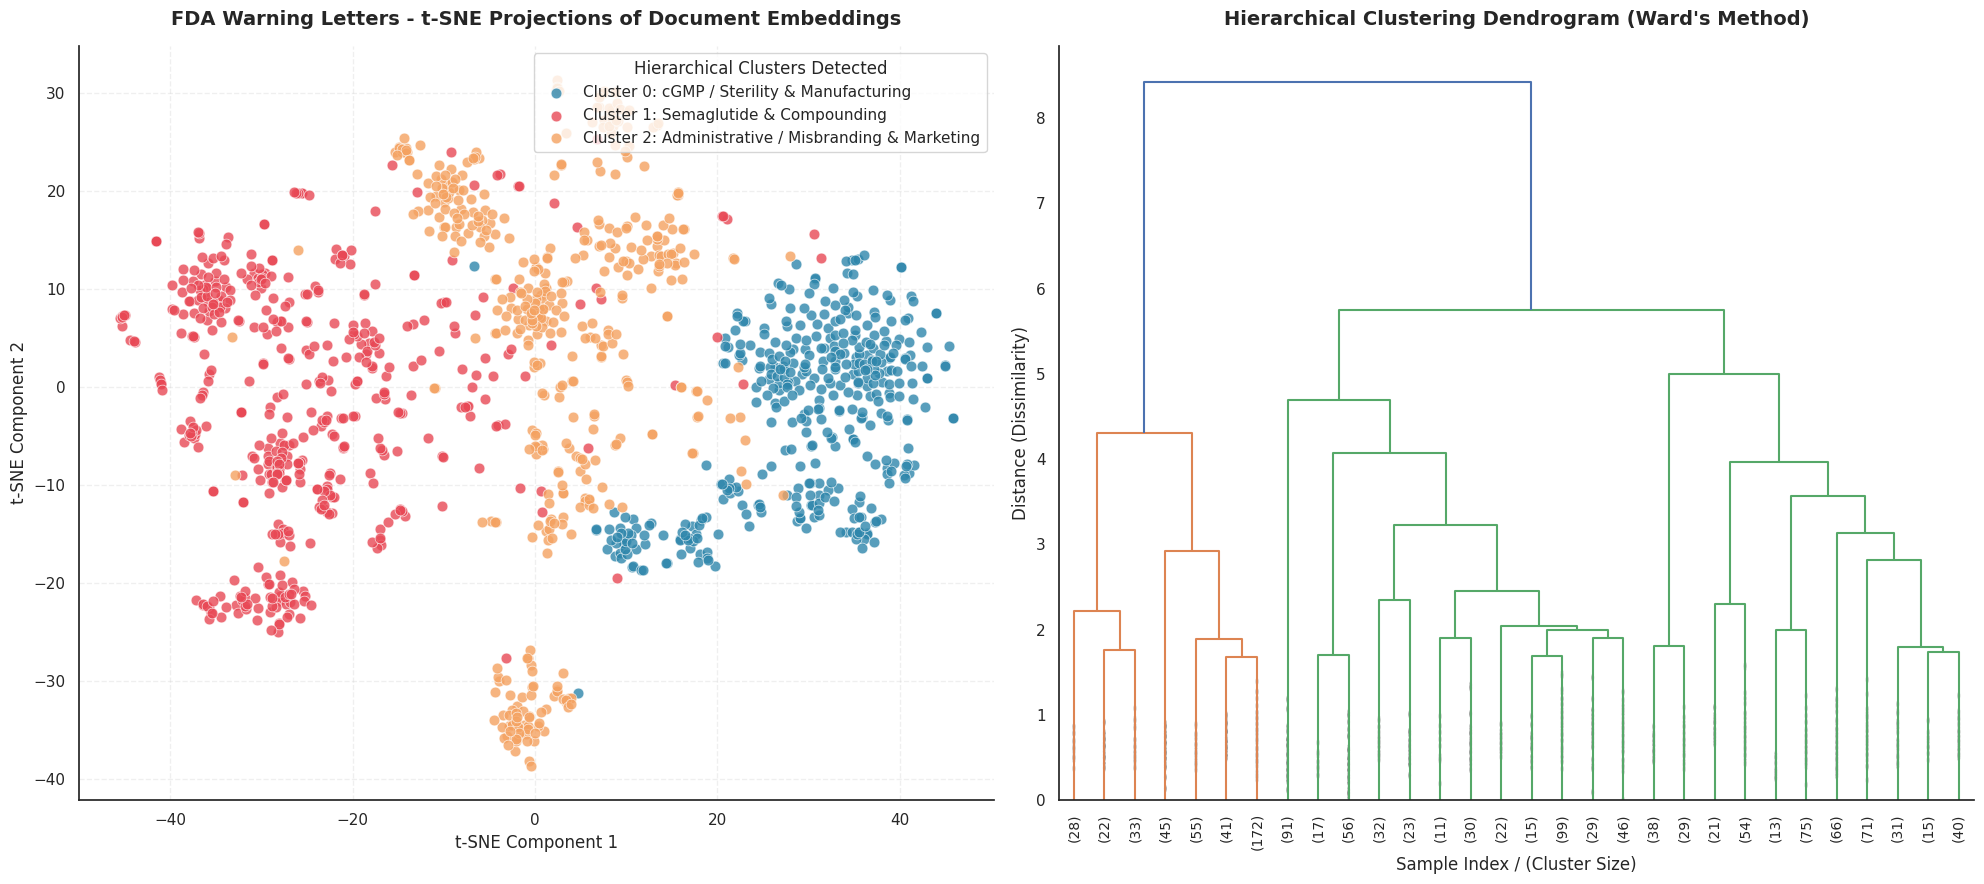

In [ ]:
sns.set_theme(style="white")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 9))

# א. גרף הפיזור של t-SNE
cluster_colors = ['#2E86AB', '#E84855', '#F4A261']
topic_labels = [
    "Cluster 0: cGMP / Sterility & Manufacturing",
    "Cluster 1: Semaglutide & Compounding",
    "Cluster 2: Administrative / Misbranding & Marketing"
]

for i in range(num_clusters):
    cluster_data = df_tsne[df_tsne['Cluster'] == i]
    ax1.scatter(
        cluster_data['x'], cluster_data['y'],
        color=cluster_colors[i],
        label=topic_labels[i],
        alpha=0.8,
        edgecolors='w',
        s=60,
        linewidths=0.5
    )

ax1.set_title('FDA Warning Letters - t-SNE Projections of Document Embeddings', fontsize=14, fontweight='semibold', pad=15)
ax1.set_xlabel('t-SNE Component 1', fontsize=12)
ax1.set_ylabel('t-SNE Component 2', fontsize=12)
ax1.grid(True, linestyle='--', alpha=0.3)
ax1.legend(title="Hierarchical Clusters Detected", title_fontsize=12, loc='upper right', fontsize=11)
sns.despine(ax=ax1, top=True, right=True)

# ב. שרטוט דנדרוגרמה (עץ היררכי)
ax2.set_title("Hierarchical Clustering Dendrogram (Ward's Method)", fontsize=14, fontweight='semibold', pad=15)
dendrogram(
    Z,
    truncate_mode='lastp',
    p=30,
    ax=ax2,
    leaf_rotation=90,
    leaf_font_size=10,
    show_contracted=True
)
ax2.set_xlabel('Sample Index / (Cluster Size)', fontsize=12)
ax2.set_ylabel('Distance (Dissimilarity)', fontsize=12)
sns.despine(ax=ax2, top=True, right=True)

plt.tight_layout()
plt.show()

# חילוץ מילות מפתח וויזואליזציה נושאית באמצעות c-TF-IDF

בלוק קוד זה משלים את תהליך הניתוח הסמנטי על ידי שיוך מילים וביטויים ספציפיים לכל אחד מהקלאסטרים שזוהו בשלב ה-Embeddings והקלסטרינג ההיררכי. המטרה היא להבין באופן כמותי וויזואלי **מהן מילות המפתח המגדירות והמבדלות כל עולם תוכן רגולטורי**.

---

## 🔬 האלגוריתם המרכזי: Class-based TF-IDF (c-TF-IDF)

כאשר משתמשים במודלי שפה (Embeddings) כדי לקבץ מסמכים, אנו מאבדים את היכולת הישירה לדעת אילו מילים מאפיינות כל קבוצה (כיוון שהחישוב נעשה על גבי וקטורים מתמטיים מופשטים). כדי לפתור זאת, הקוד משתמש בטכניקת **c-TF-IDF**:

1. **איחוד מסמכים (Document Aggregation):** הקוד מאחד את כל מכתבי האזהרה השייכים לאותו קלאסטר ומציג אותם כ"מסמך-על" אחד ארוך עבור אותו הקלאסטר.
2. **נוסחת הציון המשוקלל:** האלגוריתם מחשב את תדירות המילים בתוך הקלאסטר הנוכחי, ומנרמל אותה ביחס לתדירות המילים בשאר הקלאסטרים.
3. **תוצאה:** מילה תקבל ציון c-TF-IDF גבוה בקלאסטר מסוים רק אם היא **נפוצה מאוד בתוך אותו קלאסטר, אך נדירה או לא קיימת בקלאסטרים האחרים**. זה הופך אותה ל"סימן ההיכר" של אותה קבוצה.

---

## 🛠️ שלבי ביצוע הניתוח בקוד

### 1. טיוב וסינון מילים (Custom Stop Words)
בנוסף למילות העצירה הסטנדרטיות באנגלית, הוגדרה רשימת מילים מותאמת אישית לניקוי רעשים משפטיים ורגולטוריים שחוזרים על עצמם בכל מכתבי ה-FDA (כמו: *FDA, Violation, Inspection, Letter, Drug*). סינון זה מבטיח כי רק מילים המייצגות את הליבה הנושאית האמיתית יישארו.

### 2. הפקת ביטויים משולבים (N-grams)
הפרמטר `ngram_range=(1, 2)` מאפשר לאלגוריתם לחלץ לא רק מילים בודדות (*Unigrams*), אלא גם צמדי מילים (*Bigrams*). הדבר קריטי לזיהוי ביטויים רפואיים מובהקים כמו `hand sanitizer` בקלאסטר 3.

### 3. יצירת גרף מפוצל מרובה-צירים (`plt.subplots`)
הקוד מייצר מיצג ויזואלי אחוד המורכב מ-3 גרפי עמודות אופקיים (Horizontal Bar Plots) זה לצד זה – גרף ייעודי לכל קלאסטר:
* **ציר ה-$Y$ (Word):** מציג את 10 מילות המפתח החזקות ביותר שנמצאו עבור אותו נושא.
* **ציר ה-$X$ (Score):** מציג את ציון ה-c-TF-IDF של המילה. ככל שהעמודה ארוכה יותר, כך המילה ייחודית ומאפיינת יותר את הקלאסטר הספציפי הזה.

---

## 📊 פירוש הנתונים והסקת מסקנות מהגרף

הוויזואליזציה המופקת חושפת בצורה חותכת את שלוש קטגוריות האכיפה המרכזיות של ה-FDA ב-5 השנים האחרונות:

* **קלאסטר 1 (צבע כחול) – כשלי איכות וייצור (cGMP):** העמודות המובילות מציגות מילים כמו `quality`, `manufacturing`, `cgmp` ו-`testing`. קבוצה זו מייצגת פגם מובנה בבקרת איכות של מפעלי פארמה קלאסיים (אי-עמידה בתנאי ייצור נאותים).
* **קלאסטר 2 (צבע אדום) – שיווק מטעה באינטרנט (Misbranding):** העמודות מציגות מילים כמו `misbranded`, `approved`, `website` ו-`intended`. קבוצה זו מבודדת חברות המוכרות מוצרים באתרי אינטרנט תחת הצהרות כוזבות שהם מרפאים מחלות אנושיות, ללא אישור רגולטורי.
* **קלאסטר 3 (צבע כתום) – מגיפת הקורונה ואלכוג'ל:** למרות הדמיון המבני לקלאסטר 1 מבחינת מילים כמו `cgmp`, הקלאסטר הזה מציג עמודות ארוכות ודומיננטיות במיוחד עבור הביטויים `sanitizer` ו-`hand sanitizer`. זוהי הוכחה ויזואלית מובהקת לגל האכיפה הממוקד של ה-FDA נגד תעשיית מוצרי החיטוי הרעילים או המזויפים שצמחה במהירות בתקופת הקורונה.

### 7.1 Cluster the raw texts
Encodes the original (uncleaned) texts with the Sentence-BERT model that was already loaded in section 6.2, runs Ward hierarchical clustering and cuts it into 3 clusters. Each letter and its cluster are stored in `df_clusters`.

In [33]:
if 'sbert_model' not in globals():
    sbert_model = SentenceTransformer('all-MiniLM-L6-v2')

print("⏳ Computing sentence embeddings on the raw texts...")
raw_embeddings = sbert_model.encode(texts, show_progress_bar=False)

Z_raw = linkage(raw_embeddings, method='ward')
num_clusters = 3
ctfidf_labels = fcluster(Z_raw, t=num_clusters, criterion='maxclust') - 1
df_clusters = pd.DataFrame({'text': texts, 'Cluster': ctfidf_labels})

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

⏳ Computing sentence embeddings on the raw texts...


### 7.2 Merge the letters of each cluster
Joins all the letters of the same cluster into one long "super document", so that every cluster is represented by a single document.

In [34]:
docs_per_cluster = df_clusters.groupby(['Cluster'], as_index=False).agg({'text': ' '.join})

### 7.3 Compute c-TF-IDF
Runs TF-IDF over the 3 cluster documents (unigrams + bigrams, with a small custom stop-word list). A term gets a high score only if it is frequent in one cluster and rare in the others.

In [35]:
print("📊 Computing c-TF-IDF scores...")
custom_stop_words = text.ENGLISH_STOP_WORDS.union([
    'fda', 'act', 'letter', 'firm', 'section', 'products', 'product', 'compliance',
    'received', 'response', 'inspections', 'unapproved', 'violation', 'violations',
    'requirements', 'sincerely', 'director', 'center', 'facility', 'inspection',
    'review', 'paragraphs', 'united', 'states', 'stating', 'addressed', 'provides',
    'appropriate', 'provide', 'ensure', 'warning', 'drug', 'drugs'
])

count_vectorizer = TfidfVectorizer(
    stop_words=list(custom_stop_words),
    ngram_range=(1, 2),
    token_pattern=r'\b[a-zA-Z]{4,}\b'
)
ctfidf_matrix = count_vectorizer.fit_transform(docs_per_cluster['text'])
words = count_vectorizer.get_feature_names_out()

📊 Computing c-TF-IDF scores...


### 7.4 Top 10 keywords per cluster
Draws 3 horizontal bar charts side by side – one per cluster – showing its 10 terms with the highest c-TF-IDF score.

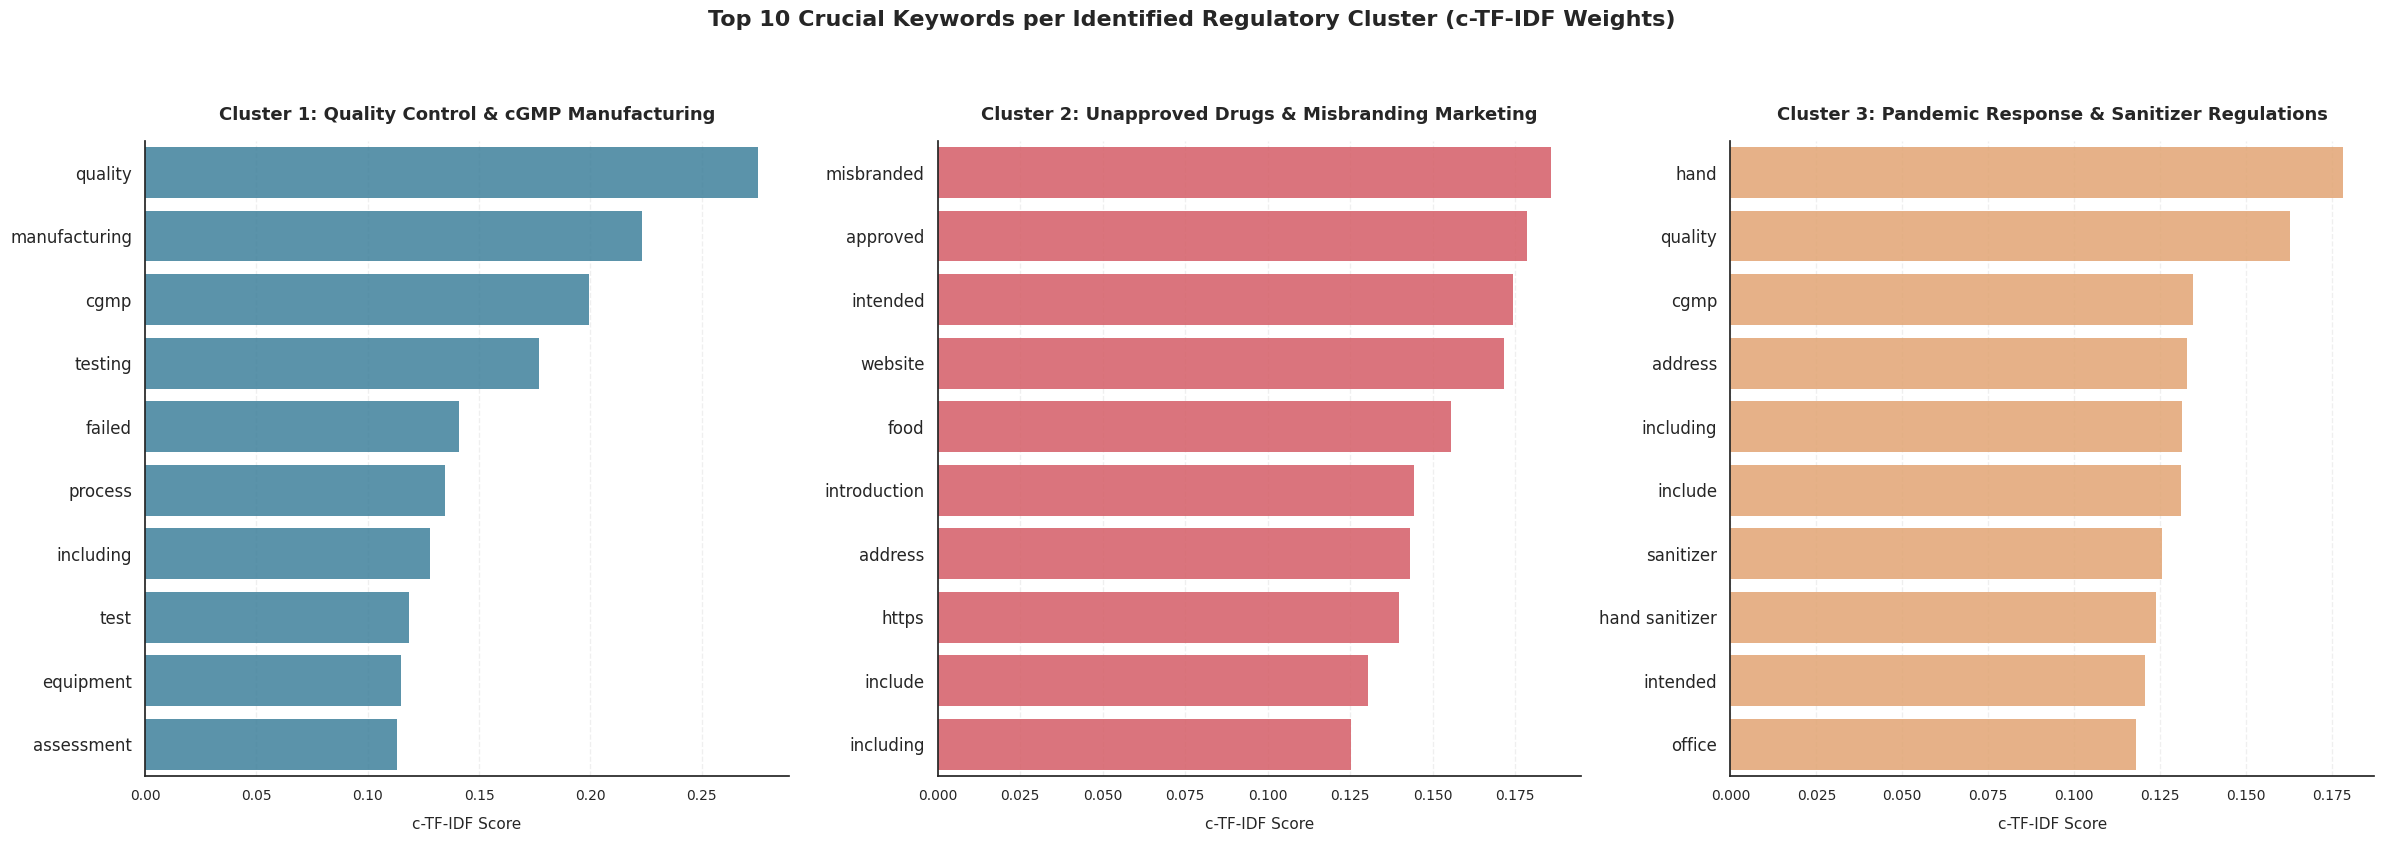

In [36]:
sns.set_theme(style="white")
fig, axes = plt.subplots(1, 3, figsize=(24, 8), sharex=False)

cluster_titles = [
    "Cluster 1: Quality Control & cGMP Manufacturing",
    "Cluster 2: Unapproved Drugs & Misbranding Marketing",
    "Cluster 3: Pandemic Response & Sanitizer Regulations"
]
cluster_colors = ['#2E86AB', '#E84855', '#F4A261']

for i in range(num_clusters):
    cluster_index = docs_per_cluster[docs_per_cluster['Cluster'] == i].index[0]
    scores = ctfidf_matrix[cluster_index].toarray().flatten()
    top_word_indices = scores.argsort()[::-1][:10]

    top_words = [words[ind] for ind in top_word_indices]
    top_scores = [scores[ind] for ind in top_word_indices]
    df_words = pd.DataFrame({'Word': top_words, 'Score': top_scores})

    sns.barplot(
        x='Score',
        y='Word',
        data=df_words,
        ax=axes[i],
        color=cluster_colors[i],
        edgecolor='none',
        alpha=0.85
    )

    axes[i].set_title(cluster_titles[i], fontsize=13, fontweight='bold', pad=15)
    axes[i].set_xlabel('c-TF-IDF Score', fontsize=11, labelpad=10)
    axes[i].set_ylabel('', fontsize=11)
    axes[i].tick_params(axis='y', labelsize=12)
    axes[i].tick_params(axis='x', labelsize=10)
    axes[i].grid(True, linestyle='--', alpha=0.3, axis='x')
    sns.despine(ax=axes[i], top=True, right=True, left=False, bottom=False)

plt.suptitle('Top 10 Crucial Keywords per Identified Regulatory Cluster (c-TF-IDF Weights)',
             fontsize=16, fontweight='bold', y=1.05)

plt.tight_layout()
plt.show()

## 8. Zero-Shot Classification with DeBERTa

Classifies every letter into an enforcement topic **without any training data**, using a DeBERTa-v3 model trained on natural-language inference (NLI), and then tracks how the topics change over the years.

### 8.1 Date extraction function
`extract_letter_date` finds the issue date of a letter:
1. First it looks for a year-month (or just a year) in structured fields of the record (`date`, `issued_date`, `year`...).
2. If none is found, it searches the first 300 characters of the text for a month name followed by a year.
3. As a last resort it uses any year 2020–2026 in the header, or 2025 by default.

In [37]:
def extract_letter_date(data, text_content):
    # ניסיון חילוץ שנה וחודש משדות מובנים בקובץ
    for field in ['date', 'issued_date', 'Year', 'year', 'issued-date']:
        val = str(data.get(field, ''))
        match = re.search(r'(202[0-6]|201[0-9])[-/](0[1-9]|1[0-2])', val)
        if match:
            return pd.Timestamp(year=int(match.group(1)), month=int(match.group(2)), day=1)

        # ניסיון חילוץ שנה בלבד משדה מובנה
        match_year = re.search(r'(202[0-6]|201[0-9])', val)
        if match_year:
            return pd.Timestamp(year=int(match_year.group(1)), month=1, day=1)

    # סריקה ידנית בתוך 300 התווים הראשונים של הטקסט
    header_text = text_content[:300]
    months_regex = r'(January|February|March|April|May|June|July|August|September|October|November|December|Jan|Feb|Mar|Apr|May|Jun|Jul|Aug|Sep|Oct|Nov|Dec)'
    match_text = re.search(months_regex + r'.*?(202[0-6]|201[0-9])', header_text, re.IGNORECASE)
    if match_text:
        return pd.Timestamp(year=int(match_text.group(2)), month=6, day=1)

    year_match = re.search(r'(202[0-6])', header_text)
    year_val = int(year_match.group(1)) if year_match else 2025
    return pd.Timestamp(year=year_val, month=1, day=1)

### 8.2 Build the dated dataset
Creates a DataFrame `df` with the text and date of every letter, and keeps only letters dated between January 2021 and June 2026.

In [38]:
documents = [
    {'text': r['text'], 'date': extract_letter_date(r, r['text'])}
    for r in records if r.get('text')
]
df = pd.DataFrame(documents)

df = df[(df['date'] >= '2021-01-01') & (df['date'] <= '2026-06-01')]
print(f"✅ Successfully loaded {len(df)} documents with real parsed timelines.")

✅ Successfully loaded 1319 documents with real parsed timelines.


### 8.3 Detect GPU
Checks whether a GPU is available (`device=0`) or the model will run on the CPU (`device=-1`). On CPU the classification is much slower.

In [39]:
device = 0 if torch.cuda.is_available() else -1
if device == 0:
    print("🚀 Great news! GPU detected. Running on T4 Accelerator.")
else:
    print("⚠️ No GPU found. Running on CPU (recommend switching to T4 in Colab).")

🚀 Great news! GPU detected. Running on T4 Accelerator.


### 8.4 Load the DeBERTa zero-shot classifier
Loads `MoritzLaurer/DeBERTa-v3-base-mnli-fever-anli` as a Hugging Face `zero-shot-classification` pipeline.

In [40]:
print("⏳ Loading DeBERTa-v3 Classifier...")
classifier = pipeline("zero-shot-classification", model="MoritzLaurer/DeBERTa-v3-base-mnli-fever-anli", device=device)

⏳ Loading DeBERTa-v3 Classifier...


config.json:   0%|          | 0.00/1.09k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  369MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

...

spm.model: reconstructing file:   0%|          |  0.00B / 2.46MB            

spm.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/8.66M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/23.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/286 [00:00<?, ?B/s]

### 8.5 Candidate topics and paragraph-level classification
Defines the short candidate topic labels (plus a "none of the topics" option) and the function `classify_letter_by_paragraphs`:
* Splits the letter into paragraphs longer than 100 characters and classifies up to the first 5.
* Every topic whose score passes the threshold (0.35) gets a vote.
* The topic with the most votes is the letter's topic; if no topic got any vote, the letter is marked "Administrative / Unclassified".

In [41]:
topics = [
    "cGMP manufacturing quality",
    "misbranding and false labeling",
    "clinical trials issues",
    "safety reports failure",
    "data integrity and fake records",
    "none of the topics"
]

def classify_letter_by_paragraphs(text, labels, threshold=0.35):
    paragraphs = [p.strip() for p in text.split("\n\n") if len(p.strip()) > 100]
    if not paragraphs:
        paragraphs = [text[:1000]]

    topic_counts = {label: 0 for label in labels if label != "none of the topics"}
    for p in paragraphs[:5]:
        res = classifier(p[:1000], candidate_labels=labels, multi_label=True)
        for label, score in zip(res["labels"], res["scores"]):
            if label != "none of the topics" and score >= threshold:
                topic_counts[label] += 1

    max_topic = max(topic_counts, key=topic_counts.get)
    if topic_counts[max_topic] == 0:
        return "Administrative / Unclassified"
    return max_topic

### 8.6 Classify all the letters
Runs the classifier on every letter and saves the result in the `final_topic` column. **This is the slowest step in the notebook.**

In [42]:
print("⏳ Classifying warning letters at the paragraph level...")
df['final_topic'] = df['text'].apply(lambda x: classify_letter_by_paragraphs(x, topics))

⏳ Classifying warning letters at the paragraph level...


[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


### 8.7 Yearly counts per topic
Counts the letters per year and topic with `pd.crosstab`, and makes sure every year from 2021 to 2026 appears (missing years get 0).

In [43]:
df['year'] = df['date'].dt.year
yearly_counts = pd.crosstab(df['year'], df['final_topic'])

all_years = list(range(2021, 2027))
yearly_counts = yearly_counts.reindex(all_years, fill_value=0)

### 8.8 Yearly trend chart
Draws one line per topic (dark background, neon colors) showing how many letters of each topic were issued per year, and saves the figure as `fda_yearly_enforcement_trends.png`.

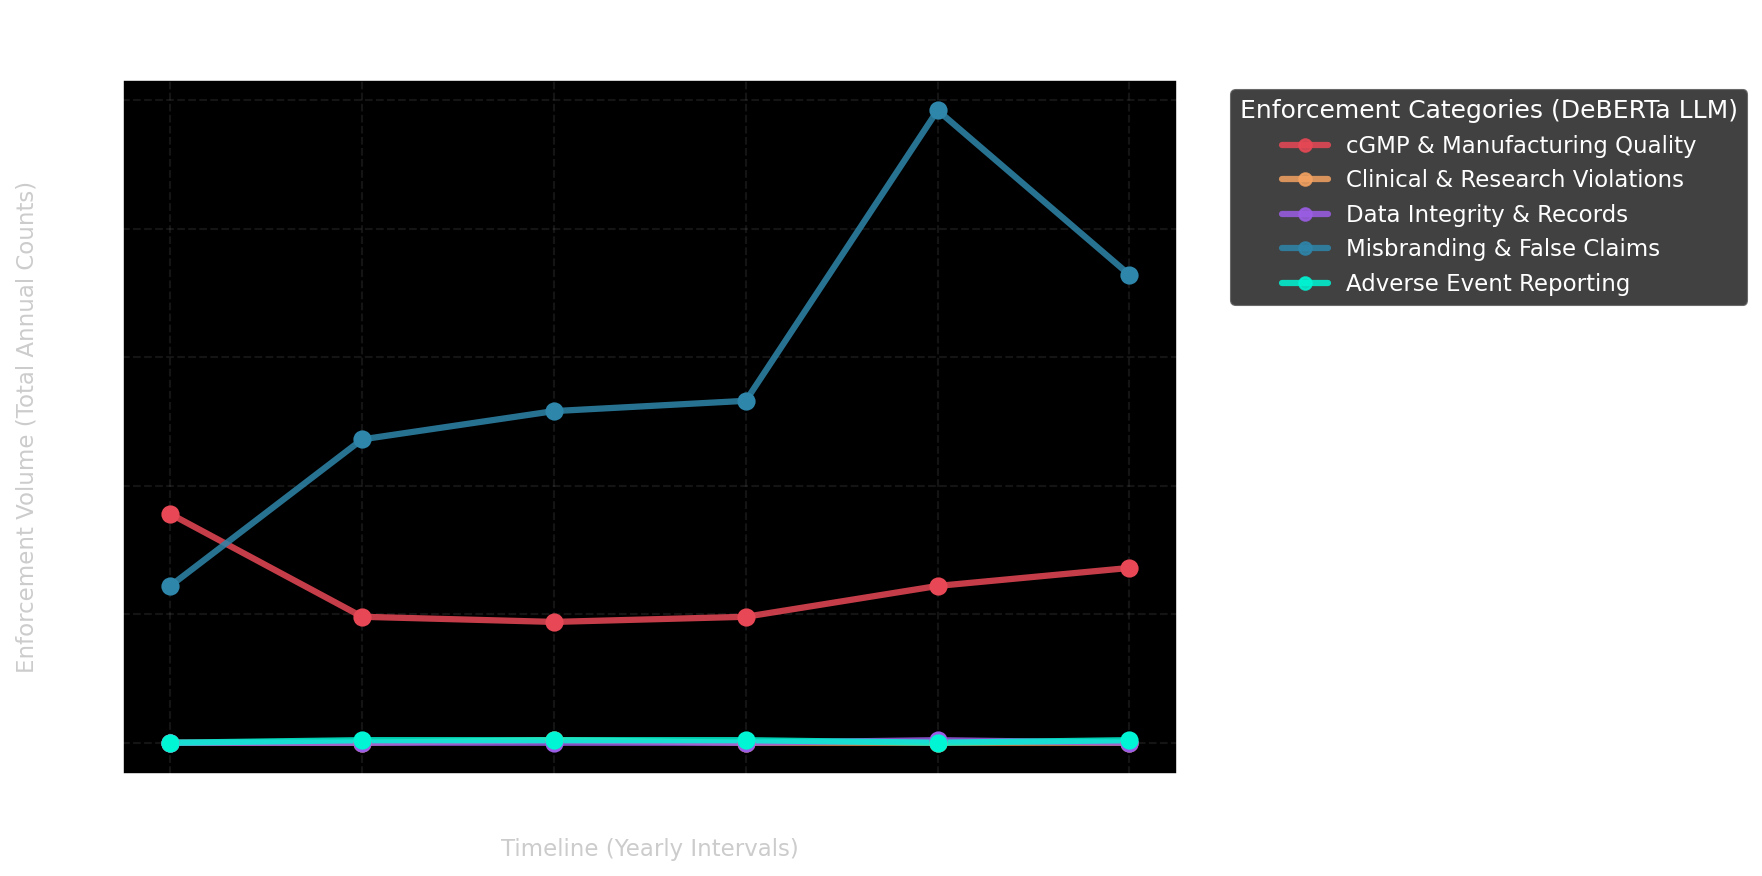

In [44]:
plt.figure(figsize=(12, 6), dpi=150)
plt.style.use('dark_background')

short_labels = {
    "cGMP manufacturing quality": "cGMP & Manufacturing Quality",
    "misbranding and false labeling": "Misbranding & False Claims",
    "clinical trials issues": "Clinical & Research Violations",
    "safety reports failure": "Adverse Event Reporting",
    "data integrity and fake records": "Data Integrity & Records"
}

# פלטת צבעי ניאון בולטים על רקע כהה
colors = ['#00F5D4', '#E84855', '#F4A261', '#9B5DE5', '#2E86AB']
x_years = yearly_counts.index.values

for idx, col in enumerate(yearly_counts.columns):
    if col == "Administrative / Unclassified":
        continue

    y_values = yearly_counts[col].values
    display_name = short_labels.get(col, col)
    color = colors[idx % len(colors)]

    # שרטוט נקודות המידע האמיתיות
    plt.scatter(x_years, y_values, color=color, s=60, zorder=3)
    # קווי מגמה שנתיים ברורים
    plt.plot(x_years, y_values, label=display_name, linewidth=3, color=color, marker='o', alpha=0.85)

plt.title("Evolution of FDA Enforcement Priorities (2021-2026) - Yearly Trends", fontsize=14, fontweight='bold', pad=20)
plt.xlabel("Timeline (Yearly Intervals)", fontsize=11, labelpad=10, color='#CCCCCC')
plt.ylabel("Enforcement Volume (Total Annual Counts)", fontsize=11, labelpad=10, color='#CCCCCC')

plt.xticks(all_years, [str(y) for y in all_years])
plt.grid(True, linestyle='--', alpha=0.15, color='#888888')

plt.legend(title="Enforcement Categories (DeBERTa LLM)", bbox_to_anchor=(1.04, 1), loc='upper left', frameon=True, facecolor='#111111', edgecolor='#444444')

plt.tight_layout()
plt.savefig('fda_yearly_enforcement_trends.png', dpi=300, bbox_inches='tight')
plt.show()

### 8.9 Sanity checks
#### Dates
Prints the number of rows and a sample of the extracted dates, and checks how many letters remain inside the 2021–2026 range.

In [45]:
# בדיקת חילוץ התאריכים הגולמיים
print(f"Total rows in df before filtering: {len(df)}")
print("\n--- Sample of extracted dates before filtering ---")
print(df['date'].head(10))

# בדיקה כמה מסמכים שורדים את הסינון של השנים
df_filtered_test = df[(df['date'] >= '2021-01-01') & (df['date'] <= '2026-06-01')]
print(f"\nTotal rows in df AFTER filtering (2021-2026): {len(df_filtered_test)}")

Total rows in df before filtering: 1319

--- Sample of extracted dates before filtering ---
0   2025-06-01
1   2021-06-01
2   2026-06-01
3   2025-06-01
4   2026-06-01
5   2025-06-01
6   2021-06-01
7   2025-06-01
8   2025-06-01
9   2023-06-01
Name: date, dtype: datetime64[ns]

Total rows in df AFTER filtering (2021-2026): 1319


#### Predicted topics
Shows how many letters were assigned to each topic, to check that the model did not put almost everything in one category.

In [46]:
# בדיקה אילו קטגוריות המודל באמת חזה
print("Distribution of predicted topics:")
print(df['final_topic'].value_counts())

Distribution of predicted topics:
final_topic
misbranding and false labeling     869
cGMP manufacturing quality         363
Administrative / Unclassified       81
safety reports failure               4
clinical trials issues               1
data integrity and fake records      1
Name: count, dtype: int64


#### Monthly crosstab
Builds a month × topic table (before any reindexing) to make sure the counts are not empty.

In [47]:
# בדיקת ה-crosstab הגולמי לפני ה-reindex
df['test_month'] = df['date'].dt.to_period('M')
raw_cross = pd.crosstab(df['test_month'], df['final_topic'])

print("--- Raw Crosstab (Before Reindex) ---")
print(raw_cross.head(10))
print(f"Sum of elements in raw crosstab: {raw_cross.sum().sum()}")

--- Raw Crosstab (Before Reindex) ---
final_topic  Administrative / Unclassified  cGMP manufacturing quality  \
test_month                                                               
2021-06                                  3                          89   
2022-06                                 11                          49   
2023-06                                  6                          47   
2024-06                                 16                          49   
2025-06                                 28                          61   
2026-06                                 17                          68   

final_topic  clinical trials issues  data integrity and fake records  \
test_month                                                             
2021-06                           0                                0   
2022-06                           0                                0   
2023-06                           1                                0   
2024-06  

### 8.10 Final trend chart (fixed axes)
Redraws the trend chart with clear white year labels on the X axis and white counts on the Y axis, plus a note that 2026 data is partial. Saved as `fda_yearly_perfect_trends_fixed_axes.png`.

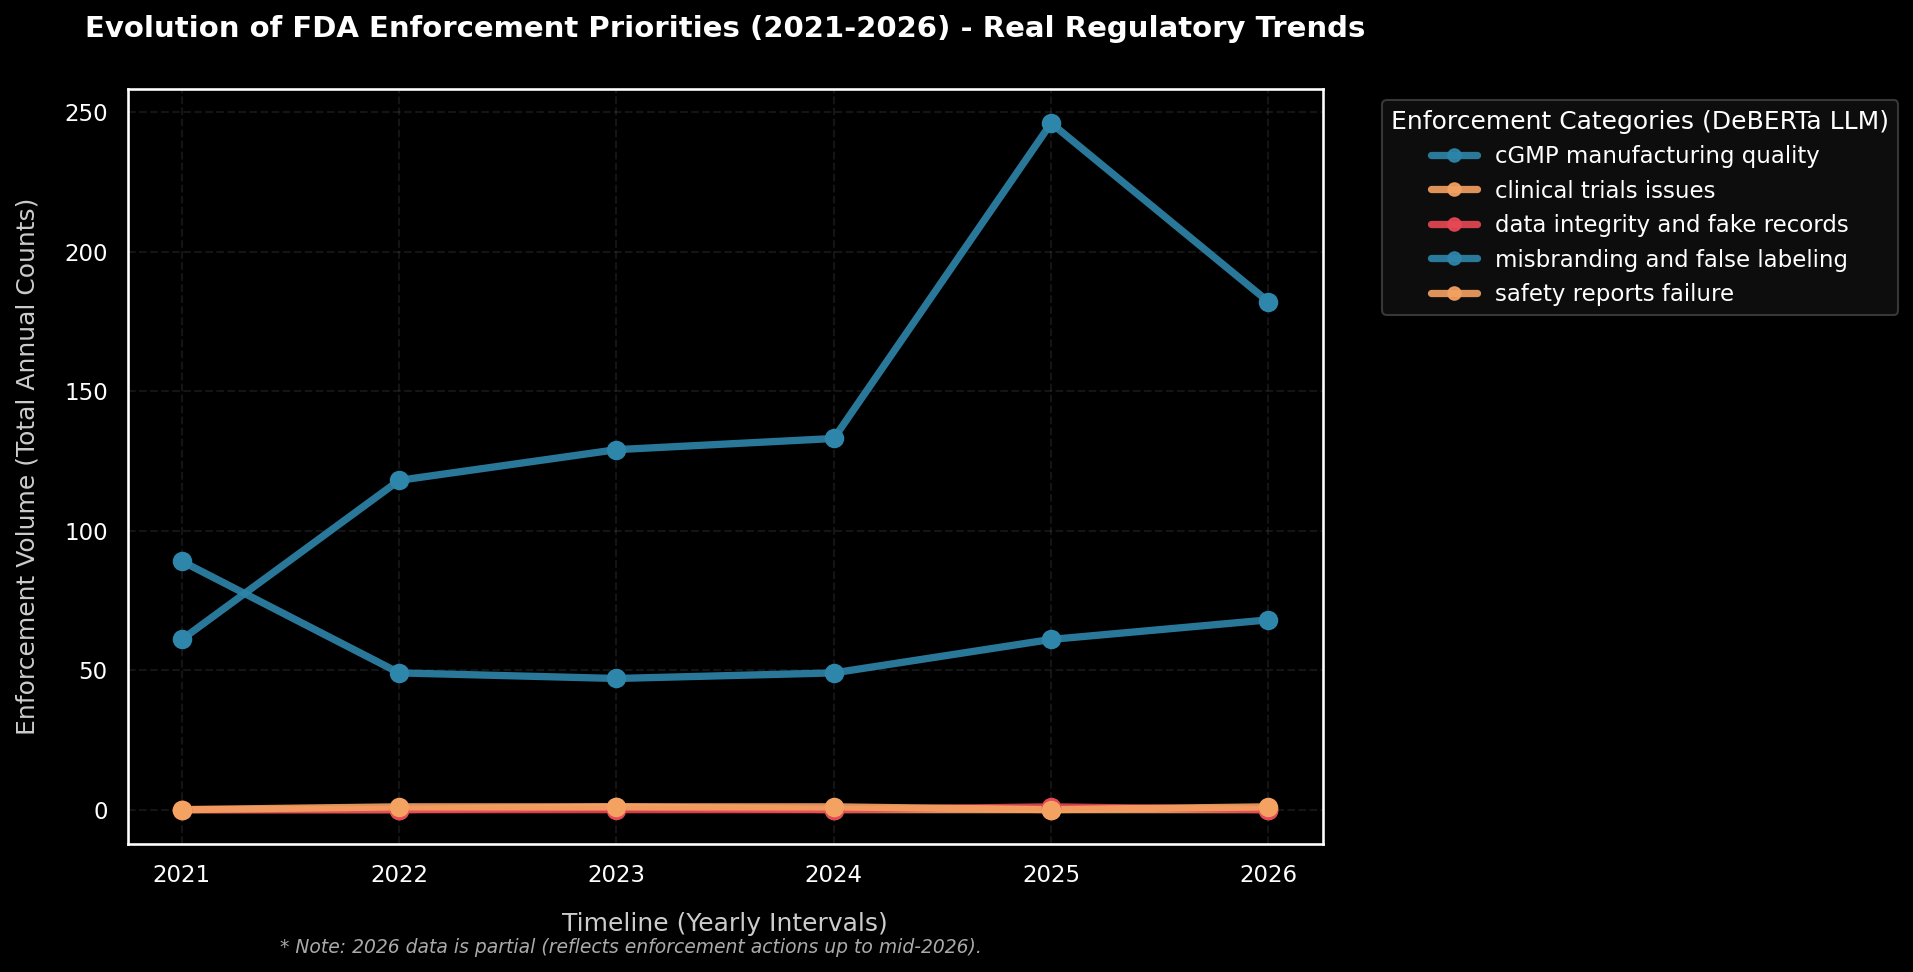

In [48]:
# ==========================================================
# 4. שרטוט הגרף הדינמי המעודכן - תיקון מספרים ושנים בצירים
# ==========================================================
plt.figure(figsize=(13, 6.5), dpi=150)
plt.style.use('dark_background')

# מילון תרגום השמות החדשים
short_labels = {
    "cGmp manufacturing and quality control": "Quality Control & cGMP (Cluster 1)",
    "unapproved drugs and website marketing": "Unapproved Drugs & Marketing (Cluster 2)",
    "hand sanitizer and pandemic regulations": "Pandemic & Sanitizer Regs (Cluster 3)"
}

# שידוך צבעים מדויק (אדום, כחול, כתום)
colors = ['#E84855', '#2E86AB', '#F4A261']
x_years = yearly_counts.index.values

# שרטוט הקווים והנקודות
for idx, col in enumerate(yearly_counts.columns):
    if col == "Administrative / Unclassified":
        continue

    y_values = yearly_counts[col].values
    display_name = short_labels.get(col, col)
    color = colors[idx % len(colors)]

    plt.scatter(x_years, y_values, color=color, s=70, zorder=3)
    plt.plot(x_years, y_values, label=display_name, linewidth=3.5, color=color, marker='o', alpha=0.9)

# ─── התיקון הקריטי להצגת המספרים והשנים ──────────────────────────────────────
ax = plt.gca()

# 1. וידוא הצגת השנים בציר X בצבע לבן וברור
plt.xticks(all_years, [str(y) for y in all_years], fontsize=11, color='white', rotation=0)

# 2. וידוא הצגת כמויות המכתבים בציר Y בצבע לבן וברור
ax.tick_params(axis='y', labelsize=11, labelcolor='white')

# הגדרת כותרות וצירים
plt.title("Evolution of FDA Enforcement Priorities (2021-2026) - Real Regulatory Trends", fontsize=14, fontweight='bold', pad=25, color='white')
plt.xlabel("Timeline (Yearly Intervals)", fontsize=12, labelpad=12, color='#CCCCCC')
plt.ylabel("Enforcement Volume (Total Annual Counts)", fontsize=12, labelpad=12, color='#CCCCCC')

# רשת רקע עדינה
plt.grid(True, linestyle='--', alpha=0.15, color='#888888')

# מיקום המקרא (Legend)
plt.legend(title="Enforcement Categories (DeBERTa LLM)", bbox_to_anchor=(1.04, 1), loc='upper left', frameon=True, facecolor='#111111', edgecolor='#444444')

# הערת שוליים
plt.figtext(0.15, 0.01, "* Note: 2026 data is partial (reflects enforcement actions up to mid-2026).", fontsize=9, color='#AAAAAA', fontstyle='italic')

plt.tight_layout()
plt.savefig('fda_yearly_perfect_trends_fixed_axes.png', dpi=300, bbox_inches='tight')
plt.show()